# Анализ и прогнозирование внешней торговли Республики Беларусь: «Арбузы свежие» (ТН ВЭД 080711)

**Цель работы:** исследовать динамику импорта и экспорта свежих арбузов (код ТН ВЭД ЕАЭС `080711`) за 2008-2021 гг., выполнить декомпозицию временных рядов, оценить взаимосвязь торговли с обменным курсом `BYN/USD` и летней погодой (2008-2024 гг.), а также построить трёхлетний прогноз на 2022-2024 гг. по 4 показателям (количество и стоимость импорта и экспорта) с помощью статистических и ML-моделей.

## 1. Источники, сбор и первичный обзор данных

1. **Белстат (`src/parse_xls.py`)** - годовые сборники внешней торговли на уровне 6 знаков ТН ВЭД (Раздел II «Продукты растительного происхождения», 2008-2021 гг.). Сборники за 2008-2016 гг. распарсены из `.pdf` (повёрнутые таблицы), за 2017-2021 гг. - из `.xls`. Все физические объёмы приведены к **тоннам** (с переводом из килограммов там, где единицей был `кг`), стоимостные - к **тыс. долл. США**. В 2010-2011 гг. код `080711` отсутствовал в таблицах экспорта, что означает нулевой объём поставок (`0,0`).
2. **НБРБ (`src/fetch_nbrb_rates.py`, `api.nbrb.by`)** - официальный ежедневный и среднегодовой курс белорусского рубля к доллару США за 2008-2024 гг. с учётом смены `Cur_ID` в 2021 г. и деноминации 1 июля 2016 г. (`10 000 BYR = 1 BYN`).
3. **Open-Meteo Archive API (`src/fetch_weather.py`)** - ежедневные метеоданные по Минску за 2008-2024 гг., агрегированные за летний сезон (средняя температура июня-августа и июля-августа, число жарких дней `>= 25°C`, сумма летних осадков).

In [ ]:
import subprocess
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", palette="deep")


def resolve_task2_root() -> Path:
    cwd = Path.cwd().resolve()
    if (cwd / "task_2").exists():
        return cwd / "task_2"
    if cwd.name == "notebooks":
        return cwd.parent
    return cwd


TASK_ROOT = resolve_task2_root()
PROCESSED_DIR = TASK_ROOT / "data" / "processed"
FIGURES_DIR = TASK_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

wm_csv = PROCESSED_DIR / "watermelons_2008_2021.csv"
if not wm_csv.exists():
    print("Файл watermelons_2008_2021.csv не найден — запускаю src/parse_xls.py...")
    subprocess.run([sys.executable, str(TASK_ROOT / "src" / "parse_xls.py")], check=True)
fx_annual_csv = PROCESSED_DIR / "nbrb_usd_annual_2008_2024.csv"
fx_daily_csv = PROCESSED_DIR / "nbrb_usd_daily_2008_2024.csv"
if not fx_annual_csv.exists() or not fx_daily_csv.exists():
    print("Файлы курсов НБРБ не найдены - запускаю src/fetch_nbrb_rates.py...")
    subprocess.run([sys.executable, str(TASK_ROOT / "src" / "fetch_nbrb_rates.py")], check=True)
df_wm = pd.read_csv(wm_csv)
df_fx_annual = pd.read_csv(PROCESSED_DIR / "nbrb_usd_annual_2008_2024.csv")
df_fx_daily = pd.read_csv(PROCESSED_DIR / "nbrb_usd_daily_2008_2024.csv", parse_dates=["date"])

# Расчёт средних контрактных цен (USD за тонну)
df_wm["import_price_usd_t"] = (df_wm["import_usd_k"] * 1000 / df_wm["import_tonnes"]).round(1)
df_wm["export_price_usd_t"] = np.where(
    df_wm["export_tonnes"] > 0,
    (df_wm["export_usd_k"] * 1000 / df_wm["export_tonnes"]).round(1),
    np.nan,
)

df = pd.merge(df_wm, df_fx_annual[["year", "byn_usd_mean", "byn_usd_std"]], on="year", how="left")

print(f"Рабочая папка задачи: {TASK_ROOT}")
print("\n=== Сводная таблица данных за 2008–2021 гг. ===")
display(df)

print("\n=== Описательные статистики целевых показателей (2008–2021 гг.) ===")
stats_cols = ["import_tonnes", "import_usd_k", "export_tonnes", "export_usd_k", "byn_usd_mean"]
desc = df[stats_cols].agg(["count", "mean", "median", "min", "max", "std"]).T.round(2)
display(desc)

Рабочая папка задачи: D:\Влад\Учеба\data-analyst-test\task_2

=== Сводная таблица данных за 2008–2021 гг. ===


,year,import_tonnes,import_usd_k,export_tonnes,export_usd_k,import_price_usd_t,export_price_usd_t,byn_usd_mean,byn_usd_std
0,2008,4014.0,745.5,3.000,1.0,185.7,333.3,0.2136,0.0022
1,2009,7592.0,1515.7,130.000,9.4,199.6,72.3,0.2792,0.0066
2,2010,19439.0,3045.4,0.000,0.0,156.7,NaN,0.2979,0.0050
3,2011,9252.0,1656.0,0.000,0.0,179.0,NaN,0.5002,0.2028
4,2012,10354.0,2319.1,68.273,26.6,224.0,389.6,0.8336,0.0169
5,2013,15351.0,3199.7,22.775,10.5,208.4,461.0,0.8881,0.0273
6,2014,19051.0,4901.1,289.000,73.2,257.3,253.3,1.0227,0.0427
7,2015,21921.0,4225.8,512.000,95.1,192.8,185.7,1.5905,0.1515
8,2016,17916.0,4522.8,83.000,14.0,252.4,168.7,1.9877,0.0742
9,2017,24780.0,4585.0,297.000,63.7,185.0,214.5,1.9324,0.0464



=== Описательные статистики целевых показателей (2008–2021 гг.) ===


,count,mean,median,min,max,std
import_tonnes,14.0,18368.00,19245.00,4014.00,31129.00,8217.89
import_usd_k,14.0,3639.56,4045.45,745.50,6936.00,1672.18
export_tonnes,14.0,130.95,63.89,0.00,512.00,162.27
export_usd_k,14.0,28.47,12.25,0.00,95.10,33.17
byn_usd_mean,14.0,1.33,1.31,0.21,2.54,0.84


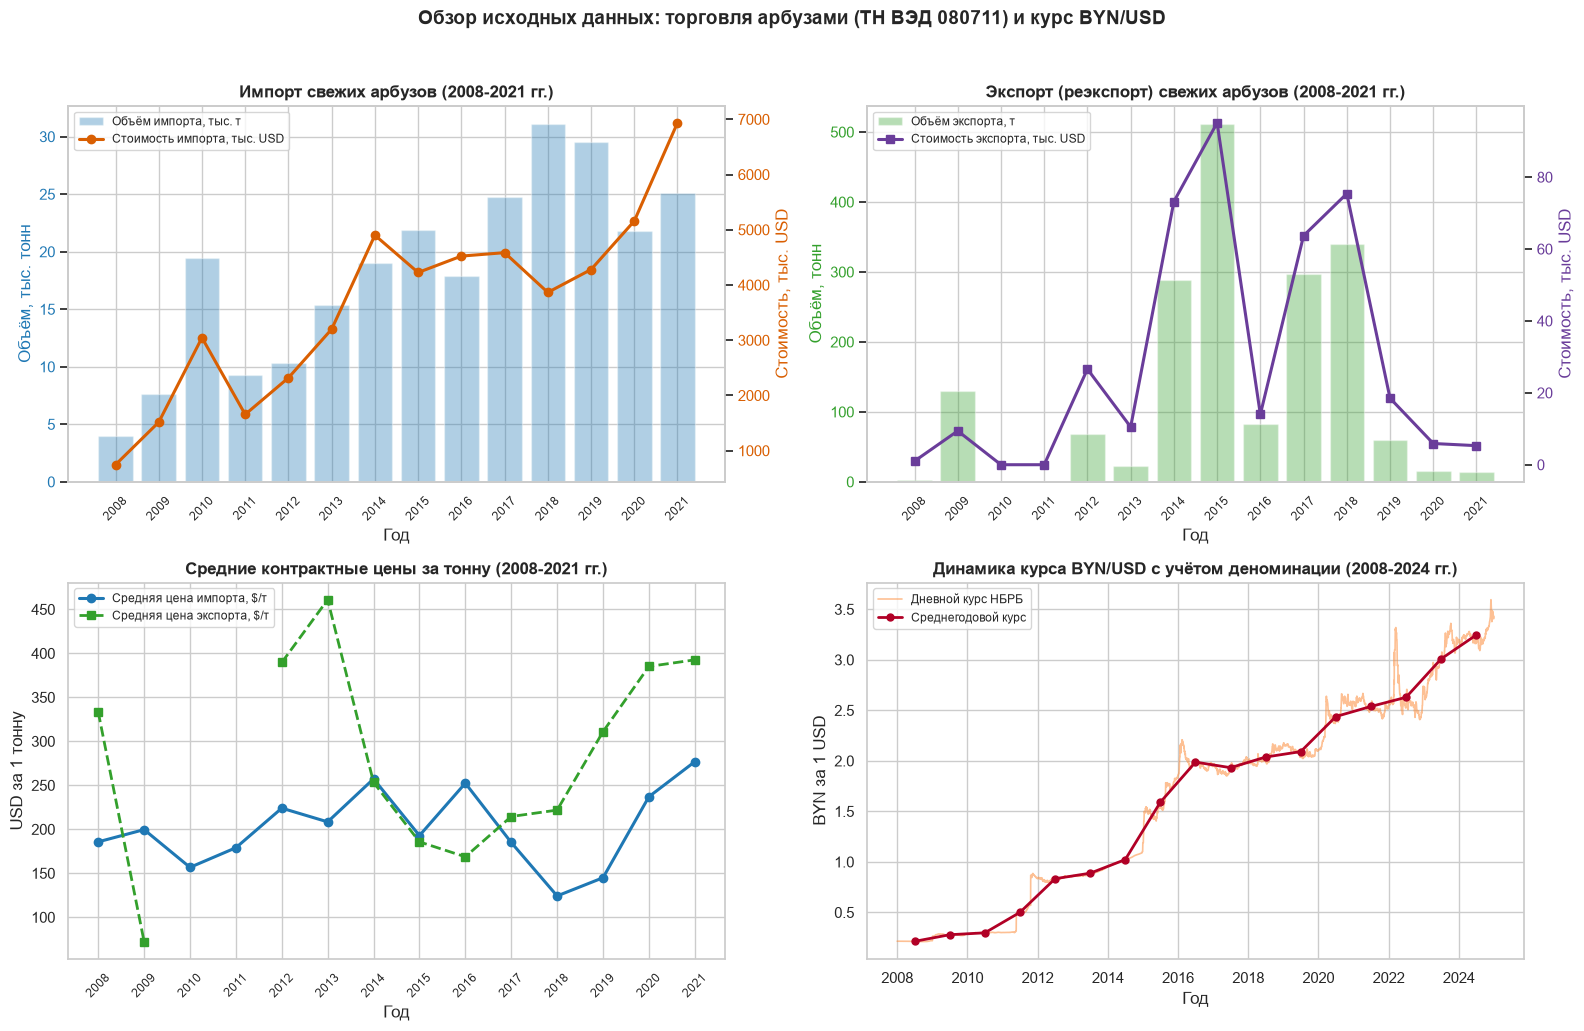

График сохранен: D:\Влад\Учеба\data-analyst-test\task_2\figures\01_raw_series_overview.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10.5))

# 1. Импорт: тонны и тыс. USD
ax1 = axes[0, 0]
b_imp = ax1.bar(df["year"], df["import_tonnes"] / 1000.0, alpha=0.35, color="#1f78b4", label="Объём импорта, тыс. т")
ax1.set_title("Импорт свежих арбузов (2008-2021 гг.)", fontweight="bold")
ax1.set_xlabel("Год")
ax1.set_ylabel("Объём, тыс. тонн", color="#1f78b4")
ax1.tick_params(axis="y", labelcolor="#1f78b4")
ax1.set_xticks(df["year"])
ax1.tick_params(axis="x", rotation=45, labelsize=8.5)

ax1_r = ax1.twinx()
l_imp = ax1_r.plot(df["year"], df["import_usd_k"], color="#d95f02", marker="o", linewidth=2.2, label="Стоимость импорта, тыс. USD")
ax1_r.set_ylabel("Стоимость, тыс. USD", color="#d95f02")
ax1_r.tick_params(axis="y", labelcolor="#d95f02")
ax1_r.grid(False)
h1 = [b_imp] + l_imp
ax1.legend(h1, [h.get_label() for h in h1], loc="upper left", fontsize=8.5)

# 2. Экспорт: тонны и тыс. USD
ax2 = axes[0, 1]
b_exp = ax2.bar(df["year"], df["export_tonnes"], alpha=0.35, color="#33a02c", label="Объём экспорта, т")
ax2.set_title("Экспорт (реэкспорт) свежих арбузов (2008-2021 гг.)", fontweight="bold")
ax2.set_xlabel("Год")
ax2.set_ylabel("Объём, тонн", color="#33a02c")
ax2.tick_params(axis="y", labelcolor="#33a02c")
ax2.set_xticks(df["year"])
ax2.tick_params(axis="x", rotation=45, labelsize=8.5)

ax2_r = ax2.twinx()
l_exp = ax2_r.plot(df["year"], df["export_usd_k"], color="#6a3d9a", marker="s", linewidth=2.2, label="Стоимость экспорта, тыс. USD")
ax2_r.set_ylabel("Стоимость, тыс. USD", color="#6a3d9a")
ax2_r.tick_params(axis="y", labelcolor="#6a3d9a")
ax2_r.grid(False)
h2 = [b_exp] + l_exp
ax2.legend(h2, [h.get_label() for h in h2], loc="upper left", fontsize=8.5)

# 3. Средние контрактные цены (USD за тонну)
ax3 = axes[1, 0]
ax3.plot(df["year"], df["import_price_usd_t"], marker="o", linewidth=2.2, color="#1f78b4", label="Средняя цена импорта, $/т")
ax3.plot(df["year"], df["export_price_usd_t"], marker="s", linewidth=2.0, linestyle="--", color="#33a02c", label="Средняя цена экспорта, $/т")
ax3.set_title("Средние контрактные цены за тонну (2008-2021 гг.)", fontweight="bold")
ax3.set_xlabel("Год")
ax3.set_ylabel("USD за 1 тонну")
ax3.set_xticks(df["year"])
ax3.tick_params(axis="x", rotation=45, labelsize=8.5)
ax3.legend(loc="upper left", fontsize=8.5)

# 4. Ежедневный и среднегодовой курс BYN/USD (2008-2024 гг.)
ax4 = axes[1, 1]
ax4.plot(df_fx_daily["date"], df_fx_daily["byn_per_usd"], color="#fd8d3c", alpha=0.55, linewidth=1.2, label="Дневной курс НБРБ")
ax4.plot(
    pd.to_datetime(df_fx_annual["year"].astype(str) + "-07-01"),
    df_fx_annual["byn_usd_mean"],
    color="#b10026", marker="o", markersize=5, linewidth=2.0, label="Среднегодовой курс"
)
ax4.set_title("Динамика курса BYN/USD с учётом деноминации (2008-2024 гг.)", fontweight="bold")
ax4.set_xlabel("Год")
ax4.set_ylabel("BYN за 1 USD")
ax4.legend(loc="upper left", fontsize=8.5)

plt.suptitle("Обзор исходных данных: торговля арбузами (ТН ВЭД 080711) и курс BYN/USD", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
raw_fig_path = FIGURES_DIR / "01_raw_series_overview.png"
plt.savefig(raw_fig_path, dpi=200)
plt.show()
print(f"График сохранен: {raw_fig_path}")

### Выводы по первичному обзору данных

1. **Рынок целиком импортоориентированный:** средний годовой импорт (`18 368 т` на сумму `3 639,6 тыс. USD`) превышает экспорт (`131 т` на сумму `28,5 тыс. USD`) более чем в 130 раз. За 2008-2021 гг. физический ввоз вырос с `4,0 тыс. т` до `25,1 тыс. т` (с пиком `31,1 тыс. т` в 2018 г.), а валютные затраты - с `0,75 млн $` почти до `6,94 млн $`.
2. **Расхождение тонн и долларов из-за закупочных цен:** в 2018 г. страна ввезла рекордный объём по минимальной средней цене (`124,2 $/т`), тогда как в 2020-2021 гг. средняя цена импорта выросла более чем вдвое (до `237,0` и `276,8 $/т` на фоне удорожания логистики), что привело к рекордному стоимостному чеку при меньшем тоннаже.
3. **Эпизодическая природа экспорта:** среднее (`130,95 т`) вдвое выше медианы (`63,89 т`) при высоком разбросе (`std = 162,27 т`) и нулях в 2010-2011 гг. Активность сосредоточена в окне 2014-2018 гг. (реэкспортные волны в РФ), после чего к 2020-2021 гг. объёмы сходят почти к нулю (`13,5-15,3 т`).

## 2. Декомпозиция временных рядов

У нас годовые данные (14 точек с 2008 по 2021 год). Арбузы — товар явно сезонный, основной ввоз идёт летом, но в годовой статистике эта сезонность не видна, потому что все месяцы уже сложены в одну цифру за год. Из-за этого сезонная компонента в стандартной декомпозиции (`period=1`) просто равна нулю.

Поэтому для каждого из 4 рядов делаем разложение на три части:
- **тренд** — выделяем через фильтр Ходрика–Прескотта (`hpfilter`, `lamb=6.25` — стандартный параметр для годовых данных), чтобы получить плавную линию без резких скачков;
- **сезонность** — показываем для порядка, что на годовом шаге она нулевая;
- **остатки (цикл и разовые колебания)** — разница между фактом и трендом. Здесь хорошо видны удачные или провальные годы, влияние цен и внешние шоки.

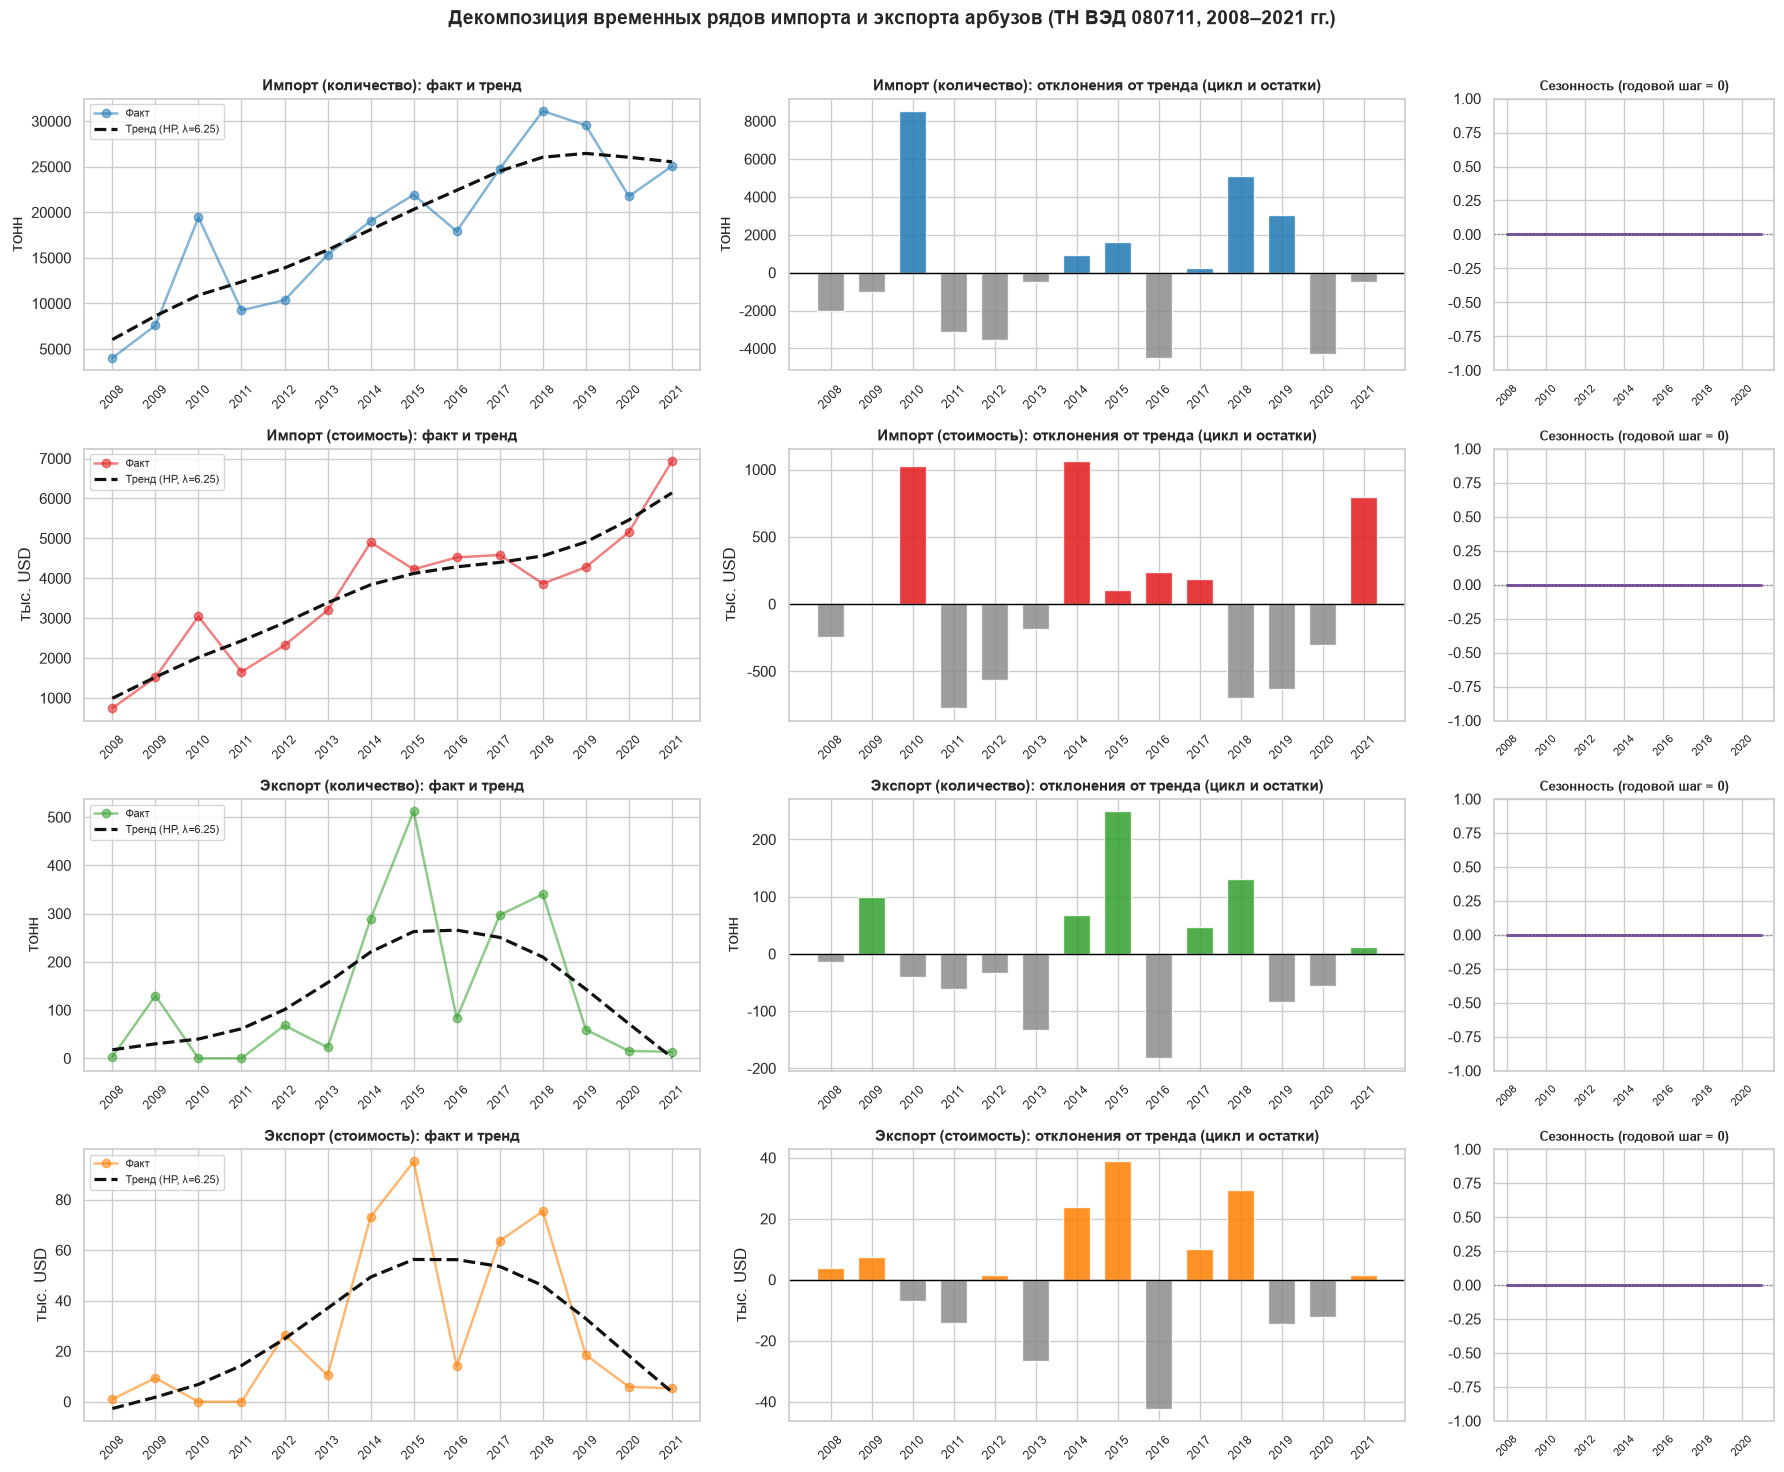

График сохранён: D:\Влад\Учеба\data-analyst-test\task_2\figures\02_decomposition.png



,Показатель,Тренд 2008,Тренд 2021,"Доля тренда в дисперсии, %",Макс. всплеск (год),Макс. спад (год)
0,Импорт (количество) (тонн),6031.2,25544.3,79.7,+8537.1 (2010),-4500.4 (2016)
1,Импорт (стоимость) (тыс. USD),991.8,6140.6,86.5,+1062.9 (2014),-774.1 (2011)
2,Экспорт (количество) (тонн),17.7,1.8,52.0,+249.2 (2015),-182.7 (2016)
3,Экспорт (стоимость) (тыс. USD),-2.7,3.8,56.5,+38.8 (2015),-42.2 (2016)


In [3]:
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.seasonal import seasonal_decompose

series_info = [
    ("import_tonnes", "Импорт (количество)", "тонн", "#1f78b4"),
    ("import_usd_k", "Импорт (стоимость)", "тыс. USD", "#e31a1c"),
    ("export_tonnes", "Экспорт (количество)", "тонн", "#33a02c"),
    ("export_usd_k", "Экспорт (стоимость)", "тыс. USD", "#ff7f00"),
]

decomp_summary = []
years = df["year"].values
dt_index = pd.date_range("2008-01-01", periods=len(df), freq="YS")

# Убираем sharex=True и делаем правую колонку (сезонность) в 2 раза уже
fig, axes = plt.subplots(
    4, 3,
    figsize=(18, 15),
    gridspec_kw={"width_ratios": [2.2, 2.2, 1.0]},
)

for i, (col, title, unit, color) in enumerate(series_info):
    y = df[col].values

    # 1. Сезонность на годовом шаге (period=1 -> всегда 0)
    s_decomp = seasonal_decompose(pd.Series(y, index=dt_index), model="additive", period=1)
    seasonal_comp = s_decomp.seasonal.values

    # 2. Плавный тренд и остатки (цикл) через фильтр Ходрика-Прескотта
    resid_cycle, trend_hp = hpfilter(y, lamb=6.25)

    trend_share = (1 - np.var(resid_cycle, ddof=1) / np.var(y, ddof=1)) * 100
    max_pos_idx = int(np.argmax(resid_cycle))
    max_neg_idx = int(np.argmin(resid_cycle))

    decomp_summary.append({
        "Показатель": f"{title} ({unit})",
        "Тренд 2008": round(trend_hp[0], 1),
        "Тренд 2021": round(trend_hp[-1], 1),
        "Доля тренда в дисперсии, %": round(trend_share, 1),
        "Макс. всплеск (год)": f"+{resid_cycle[max_pos_idx]:.1f} ({years[max_pos_idx]})",
        "Макс. спад (год)": f"{resid_cycle[max_neg_idx]:.1f} ({years[max_neg_idx]})",
    })

    # Колонка 1 (слева): Исходный ряд + Тренд
    ax_tr = axes[i, 0]
    ax_tr.plot(years, y, marker="o", color=color, alpha=0.55, linewidth=1.8, label="Факт")
    ax_tr.plot(years, trend_hp, color="#111111", linestyle="--", linewidth=2.3, label="Тренд (HP, λ=6.25)")
    ax_tr.set_title(f"{title}: факт и тренд", fontweight="bold", fontsize=10.5)
    ax_tr.set_ylabel(unit)
    ax_tr.legend(loc="upper left", fontsize=8)
    ax_tr.set_xticks(years)
    ax_tr.tick_params(axis="x", rotation=45, labelsize=8.5)

    # Колонка 2 (центр): Цикл и остатки (Факт - Тренд)
    ax_re = axes[i, 1]
    bar_colors = [color if val >= 0 else "#8c8c8c" for val in resid_cycle]
    ax_re.bar(years, resid_cycle, color=bar_colors, alpha=0.85, width=0.65)
    ax_re.axhline(0, color="black", linewidth=1)
    ax_re.set_title(f"{title}: отклонения от тренда (цикл и остатки)", fontweight="bold", fontsize=10.5)
    ax_re.set_ylabel(unit)
    ax_re.set_xticks(years)
    ax_re.tick_params(axis="x", rotation=45, labelsize=8.5)

    # Колонка 3 (справа): Сезонность (нулевая для годовых данных)
    ax_se = axes[i, 2]
    ax_se.plot(years, seasonal_comp, color="#6a3d9a", linewidth=2)
    ax_se.axhline(0, color="gray", linestyle=":", linewidth=1)
    ax_se.set_ylim(-1, 1)
    ax_se.set_title("Сезонность (годовой шаг = 0)", fontweight="bold", fontsize=9.5)
    ax_se.set_xticks(years[::2])
    ax_se.tick_params(axis="x", rotation=45, labelsize=8)

plt.suptitle("Декомпозиция временных рядов импорта и экспорта арбузов (ТН ВЭД 080711, 2008–2021 гг.)", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
decomp_fig_path = FIGURES_DIR / "02_decomposition.png"
plt.savefig(decomp_fig_path, dpi=200)
plt.show()

print(f"График сохранён: {decomp_fig_path}\n")
display(pd.DataFrame(decomp_summary))

### Что показала декомпозиция

1. **Импорт растёт стабильно и почти целиком определяется трендом.** Тренд объясняет около 80% изменений по тоннажу (рост с ~6 тыс. т в 2008 году до ~25,5 тыс. т в 2021-м) и 86,5% по стоимости (с ~1 млн до ~6,1 млн USD). Спрос на арбузы в стране системно рос все эти годы.
2. **Отклонения от тренда в импорте логично объясняются ситуацией на рынке.** Самый заметный всплеск по объёмам был в 2010 году (+8,5 тыс. т выше тренда), а сильные просадки — в кризисном 2011-м (-774 тыс. USD) и в 2016 году (-4,5 тыс. т).
3. **В экспорте стабильного тренда нет.** Там тренд описывает только половину колебаний (52–56%) и выглядит как «горб» в 2014–2018 годах, после чего снова падает почти к нулю. Самый резкий всплеск был в 2015 году (+249 т), а уже в 2016-м случился такой же резкий откат (-183 т). Это подтверждает, что экспорт арбузов — не системное производство, а разовые волны реэкспорта.

## 3. Связь торговли арбузами с курсом BYN/USD

Проверим, как курс доллара связан со стоимостью и объёмами импорта и экспорта арбузов за 2008–2021 гг.

Основной метрикой берём **корреляцию Спирмена** — она оценивает монотонную связь по рангам и не так чувствительна к резким выбросам (вроде валютных скачков 2011 и 2015 годов). **Корреляцию Пирсона** считаем рядом как вспомогательную.

Смотрим на данные в двух разрезах:
1. **По исходным значениям (уровням)** — чтобы увидеть общую картину за 14 лет.
2. **По годовым изменениям (приростам от года к году)** — чтобы убрать эффект общего тренда во времени и проверить, как рынок реально реагирует именно на резкий рост курса.

=== Корреляция торговли арбузами с курсом BYN/USD (2008–2021 гг.) ===


,Показатель,Спирмен (уровни),p-val Спирмен (уровни),Пирсон (уровни),Спирмен (изменения год к году),p-val Спирмен (изменения),Пирсон (изменения)
0,"Импорт (сумма, тыс. USD)",0.868,0.0001,0.861,-0.264,0.3839,-0.312
1,"Импорт (объём, тонны)",0.820,0.0003,0.807,-0.665,0.0132,-0.481
2,"Экспорт (сумма, тыс. USD)",0.339,0.2360,0.276,0.027,0.9290,-0.152
3,"Экспорт (объём, тонны)",0.251,0.3871,0.230,0.132,0.6676,-0.050


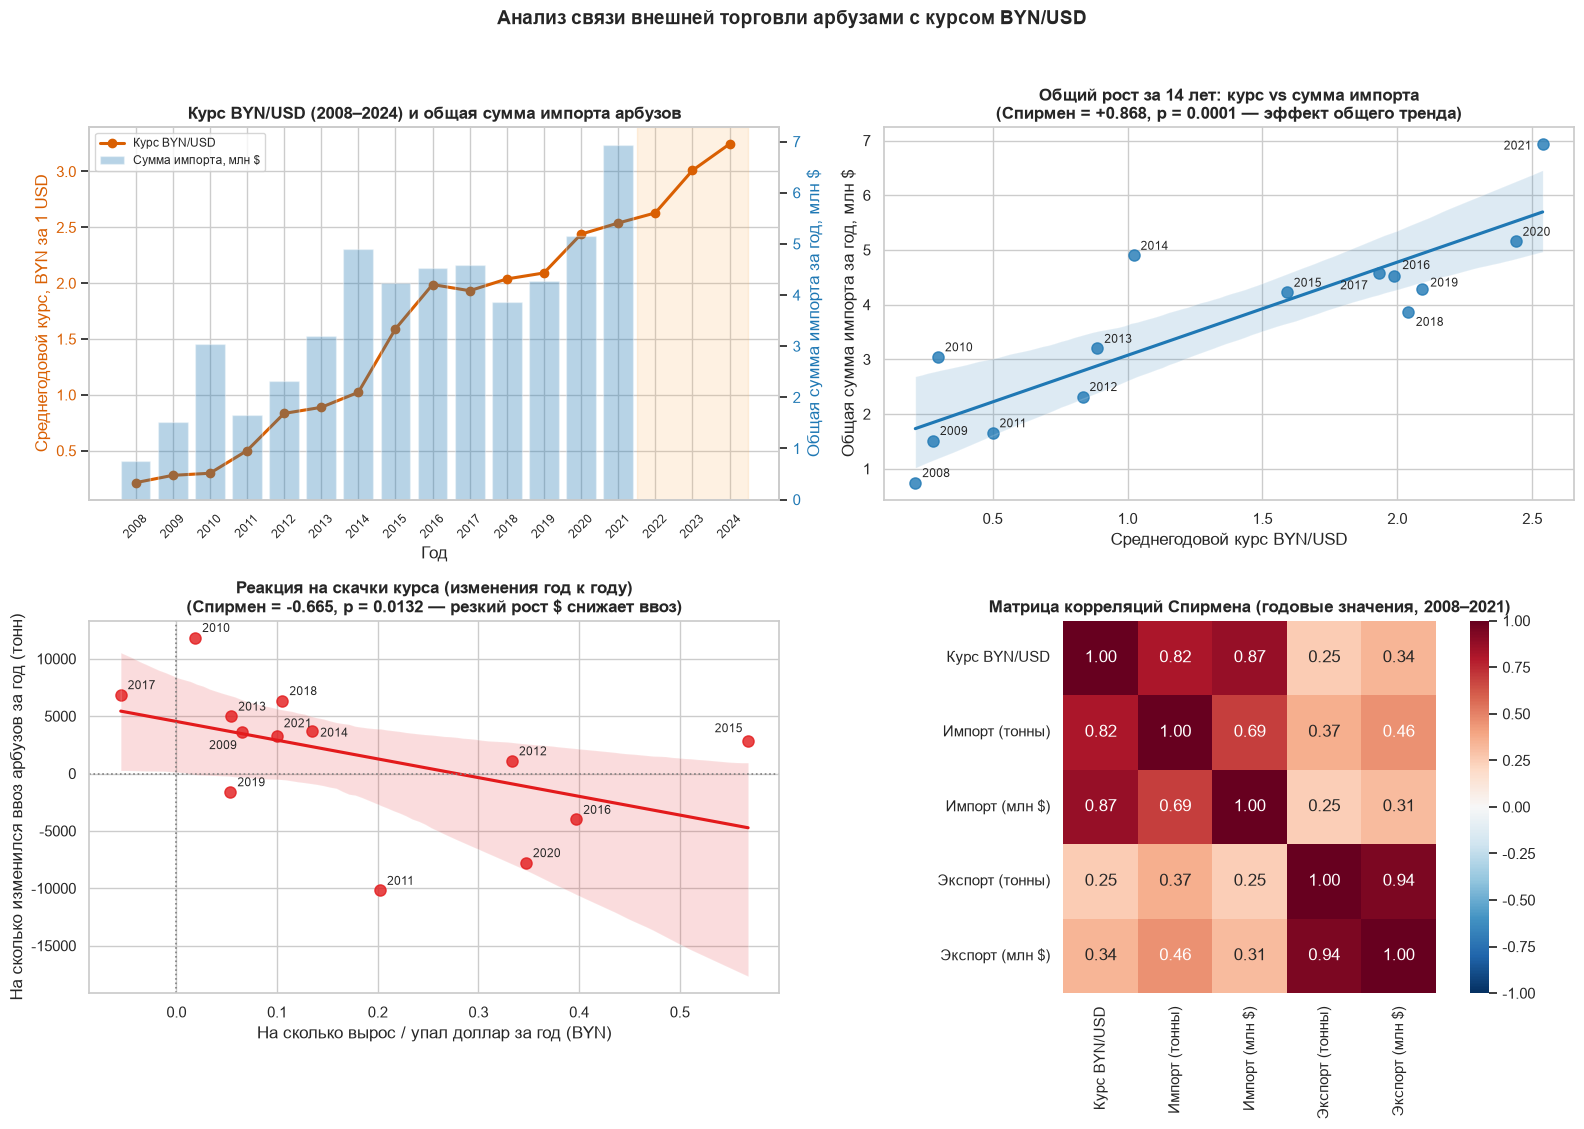

График сохранён: D:\Влад\Учеба\data-analyst-test\task_2\figures\03_fx_correlation.png


In [5]:
from scipy import stats

targets = [
    ("import_usd_k", "Импорт (сумма, тыс. USD)"),
    ("import_tonnes", "Импорт (объём, тонны)"),
    ("export_usd_k", "Экспорт (сумма, тыс. USD)"),
    ("export_tonnes", "Экспорт (объём, тонны)"),
]

# Вспомогательный столбец в млн USD для наглядности графиков
df_plot = df.copy()
df_plot["import_mln_usd"] = df_plot["import_usd_k"] / 1000.0

# Годовые изменения (2009–2021)
diff_cols = ["byn_usd_mean", "import_usd_k", "import_tonnes", "export_usd_k", "export_tonnes"]
df_diff = df[diff_cols].diff()
df_diff["year"] = df["year"]
df_diff = df_diff.dropna().reset_index(drop=True)

corr_rows = []
for col, label in targets:
    rho_lvl, ps_lvl = stats.spearmanr(df["byn_usd_mean"], df[col])
    r_lvl, p_lvl = stats.pearsonr(df["byn_usd_mean"], df[col])

    rho_dif, ps_dif = stats.spearmanr(df_diff["byn_usd_mean"], df_diff[col])
    r_dif, p_dif = stats.pearsonr(df_diff["byn_usd_mean"], df_diff[col])

    corr_rows.append({
        "Показатель": label,
        "Спирмен (уровни)": round(rho_lvl, 3),
        "p-val Спирмен (уровни)": round(ps_lvl, 4),
        "Пирсон (уровни)": round(r_lvl, 3),
        "Спирмен (изменения год к году)": round(rho_dif, 3),
        "p-val Спирмен (изменения)": round(ps_dif, 4),
        "Пирсон (изменения)": round(r_dif, 3),
    })

df_corr = pd.DataFrame(corr_rows)
df_corr.to_csv(PROCESSED_DIR / "fx_correlation_results.csv", index=False)
print("=== Корреляция торговли арбузами с курсом BYN/USD (2008–2021 гг.) ===")
display(df_corr)

# Сетка графиков 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 11.5))

# 1. Динамика курса BYN/USD (2008–2024) и общей суммы импорта (2008–2021)
ax1 = axes[0, 0]
l1 = ax1.plot(
    df_fx_annual["year"], df_fx_annual["byn_usd_mean"],
    color="#d95f02", marker="o", linewidth=2.2, label="Курс BYN/USD"
)
ax1.axvspan(2021.5, 2024.5, color="#fdb462", alpha=0.18, label="2022–2024 (горизонт прогноза)")
ax1.set_title("Курс BYN/USD (2008–2024) и общая сумма импорта арбузов", fontweight="bold")
ax1.set_xlabel("Год")
ax1.set_ylabel("Среднегодовой курс, BYN за 1 USD", color="#d95f02")
ax1.tick_params(axis="y", labelcolor="#d95f02")
ax1.set_xticks(df_fx_annual["year"])
ax1.tick_params(axis="x", rotation=45, labelsize=8.5)

ax1_r = ax1.twinx()
b1 = ax1_r.bar(df_plot["year"], df_plot["import_mln_usd"], alpha=0.32, color="#1f78b4", label="Сумма импорта, млн $")
ax1_r.set_ylabel("Общая сумма импорта за год, млн $", color="#1f78b4")
ax1_r.tick_params(axis="y", labelcolor="#1f78b4")
ax1_r.grid(False)

handles = l1 + [b1]
labels = [h.get_label() for h in handles]
ax1.legend(handles, labels, loc="upper left", fontsize=8.5)

# 2. Scatter-plot: уровни (Курс vs Сумма импорта в млн $)
ax2 = axes[0, 1]
sns.regplot(data=df_plot, x="byn_usd_mean", y="import_mln_usd", ax=ax2, color="#1f78b4", scatter_kws={"s": 65})

# Ручные сдвиги для близких точек, чтобы годы не налезали друг на друга
offsets_lvl = {
    2016: (6, 5),
    2017: (-28, -12),
    2018: (6, -10),
    2019: (6, 2),
    2021: (-28, -4),
}
for _, row in df_plot.iterrows():
    yr = int(row["year"])
    dx, dy = offsets_lvl.get(yr, (5, 4))
    ax2.annotate(str(yr), (row["byn_usd_mean"], row["import_mln_usd"]), fontsize=8.5, xytext=(dx, dy), textcoords="offset points")

rho_val = df_corr.loc[df_corr["Показатель"] == "Импорт (сумма, тыс. USD)", "Спирмен (уровни)"].values[0]
ps_val = df_corr.loc[df_corr["Показатель"] == "Импорт (сумма, тыс. USD)", "p-val Спирмен (уровни)"].values[0]
ax2.set_title(
    f"Общий рост за 14 лет: курс vs сумма импорта\n(Спирмен = {rho_val:+.3f}, p = {ps_val:.4f} — эффект общего тренда)",
    fontweight="bold"
)
ax2.set_xlabel("Среднегодовой курс BYN/USD")
ax2.set_ylabel("Общая сумма импорта за год, млн $")

# 3. Scatter-plot: изменения год к году (курс vs ввоз в тоннах)
ax3 = axes[1, 0]
sns.regplot(data=df_diff, x="byn_usd_mean", y="import_tonnes", ax=ax3, color="#e31a1c", scatter_kws={"s": 65})
ax3.axhline(0, color="gray", linestyle=":", linewidth=1.2)
ax3.axvline(0, color="gray", linestyle=":", linewidth=1.2)

offsets_diff = {
    2009: (-24, -12),
    2014: (6, -4),
    2021: (5, 6),
    2015: (-24, 6),
}
for _, row in df_diff.iterrows():
    yr = int(row["year"])
    dx, dy = offsets_diff.get(yr, (5, 4))
    ax3.annotate(str(yr), (row["byn_usd_mean"], row["import_tonnes"]), fontsize=8.5, xytext=(dx, dy), textcoords="offset points")

rho_qty_d = df_corr.loc[df_corr["Показатель"] == "Импорт (объём, тонны)", "Спирмен (изменения год к году)"].values[0]
ps_qty_d = df_corr.loc[df_corr["Показатель"] == "Импорт (объём, тонны)", "p-val Спирмен (изменения)"].values[0]
ax3.set_title(
    f"Реакция на скачки курса (изменения год к году)\n(Спирмен = {rho_qty_d:+.3f}, p = {ps_qty_d:.4f} — резкий рост $ снижает ввоз)",
    fontweight="bold"
)
ax3.set_xlabel("На сколько вырос / упал доллар за год (BYN)")
ax3.set_ylabel("На сколько изменился ввоз арбузов за год (тонн)")

# 4. Тепловая карта корреляций Спирмена (исходные годовые данные)
ax4 = axes[1, 1]
corr_cols = ["byn_usd_mean", "import_tonnes", "import_usd_k", "export_tonnes", "export_usd_k"]
corr_labels = ["Курс BYN/USD", "Импорт (тонны)", "Импорт (млн $)", "Экспорт (тонны)", "Экспорт (млн $)"]
mat = df[corr_cols].corr(method="spearman")
mat.index = corr_labels
mat.columns = corr_labels
sns.heatmap(mat, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax4)
ax4.set_title("Матрица корреляций Спирмена (годовые значения, 2008–2021)", fontweight="bold")

plt.suptitle("Анализ связи внешней торговли арбузами с курсом BYN/USD", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
fx_fig_path = FIGURES_DIR / "03_fx_correlation.png"
plt.savefig(fx_fig_path, dpi=200)
plt.show()
print(f"График сохранён: {fx_fig_path}")

### Выводы по связи торговли с курсом доллара

1. **Динамика курса и суммы импорта (верхний левый график).** На дистанции с 2008 по 2021 год оба показателя стабильно росли: среднегодовой курс доллара вырос с 0,21 до 2,54 BYN (а к 2024 году дошёл до 3,25 BYN), а общие траты страны на импорт арбузов увеличились с 0,75 млн $ почти до 7 млн $ в год. Визуально графики идут в одном направлении.
       
2. **Связь в годовых уровнях (верхний правый график).** Если сравнить годовые значения напрямую, получается сильная положительная корреляция Спирмена: +0,868 (p = 0,0001). Но делать вывод, что дорогой доллар стимулирует импорт, было бы ошибкой. Это типичный эффект общего тренда: за 14 лет одновременно росли и курс валюты, и внутренний спрос на арбузы.

3. **Реакция на скачки курса год к году (нижний левый график).** Когда мы убираем общий тренд и смотрим на годовые изменения, картина переворачивается: корреляция по тоннажу становится отрицательной и статистически значимой (Спирмен = -0,665, p = 0,013). В годы резкого роста доллара (2011, 2016 и 2020) арбузы сильно дорожали в рублях, и физический ввоз в тоннах проседал. В спокойные годы объёмы снова росли.

4. **Матрица корреляций Спирмена (нижний правый график).** Здесь хорошо видны три дополнительные детали:
   - **Экспорт от курса доллара не зависит:** значения 0,25 по тоннам и 0,34 по деньгам статистически незначимы. Это ещё раз подтверждает, что экспорт здесь представляет собой разовый реэкспорт, а не системный бизнес.
   - **Ценовой разрыв в импорте:** тонны и сумма импорта связаны умеренно (0,69), тогда как в экспорте связь почти прямая (0,94). Причина в сильных скачках закупочных цен: например, в 2018 году ввезли рекордный объём дёшево, а в 2021 году меньше тонн, но на максимальную сумму.
   - **Импорт и экспорт слабо связаны между собой (0,25-0,46):** объёмы реэкспорта не растут автоматически вместе с внутренним ввозом.

### 3.2. Дополнительный внешний фактор: летняя погода в Беларуси (2008-2024 гг.)

Помимо курса валют, спрос на арбузы внутри страны напрямую зависит от того, насколько жарким выдалось лето. Чтобы учесть этот фактор в анализе и моделях прогноза, через исторический архив `Open-Meteo API` (`src/fetch_weather.py`) были собраны ежедневные метеоданные по Минску за 2008-2024 гг. и агрегированы за летний сезон (июнь-август):
- `summer_temp_mean` - средняя температура воздуха за июнь-август (°C);
- `jul_aug_temp_mean` - средняя температура в пик сезона арбузов: июль-август (°C);
- `hot_days_25` - количество жарких дней за лето с максимальной температурой от 25°C и выше;
- `summer_rain_mm` - сумма осадков за июнь-август (мм).

=== Связь летней погоды с импортом арбузов (2008-2021 гг.) ===


,Погодный показатель,Спирмен с тоннами (уровни),p-val (уровни),Спирмен с тоннами (год к году),Спирмен с суммой $ (год к году)
0,"Средняя температура лета (июнь-август, °C)",0.410,0.1457,0.434,0.368
1,"Средняя температура пика сезона (июль-август, °C)",0.275,0.3418,0.418,0.522
2,Число жарких дней за лето (>= 25°C),0.633,0.0151,0.330,0.437
3,Сумма осадков за лето (мм),-0.222,0.4456,-0.187,-0.044


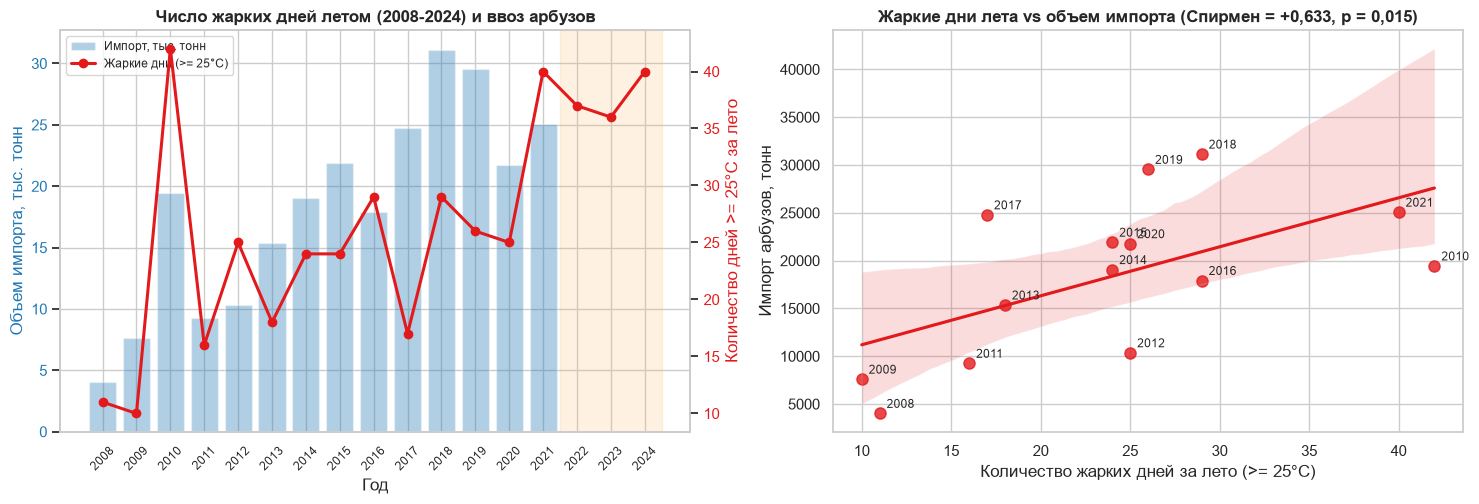

График сохранен: D:\Влад\Учеба\data-analyst-test\task_2\figures\03b_weather_impact.png


In [8]:
weather_csv = PROCESSED_DIR / "belarus_weather_2008_2024.csv"
if not weather_csv.exists():
    subprocess.run([sys.executable, str(TASK_ROOT / "src" / "fetch_weather.py")], check=True)

df_weather = pd.read_csv(weather_csv)
df_w_merged = pd.merge(df, df_weather, on="year", how="left")
df_w_diff = df_w_merged[
    ["import_tonnes", "import_usd_k", "summer_temp_mean", "jul_aug_temp_mean", "hot_days_25", "summer_rain_mm"]
].diff().dropna()

w_rows = []
w_labels = [
    ("summer_temp_mean", "Средняя температура лета (июнь-август, °C)"),
    ("jul_aug_temp_mean", "Средняя температура пика сезона (июль-август, °C)"),
    ("hot_days_25", "Число жарких дней за лето (>= 25°C)"),
    ("summer_rain_mm", "Сумма осадков за лето (мм)"),
]

for w_col, w_name in w_labels:
    rho_t_lvl, p_t_lvl = stats.spearmanr(df_w_merged[w_col], df_w_merged["import_tonnes"])
    rho_t_dif, p_t_dif = stats.spearmanr(df_w_diff[w_col], df_w_diff["import_tonnes"])
    rho_u_dif, p_u_dif = stats.spearmanr(df_w_diff[w_col], df_w_diff["import_usd_k"])
    w_rows.append({
        "Погодный показатель": w_name,
        "Спирмен с тоннами (уровни)": round(rho_t_lvl, 3),
        "p-val (уровни)": round(p_t_lvl, 4),
        "Спирмен с тоннами (год к году)": round(rho_t_dif, 3),
        "Спирмен с суммой $ (год к году)": round(rho_u_dif, 3),
    })

df_w_corr = pd.DataFrame(w_rows)
print("=== Связь летней погоды с импортом арбузов (2008-2021 гг.) ===")
display(df_w_corr)

# Визуализация: жаркие дни и температура против физического импорта
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

ax1 = axes[0]
b_imp = ax1.bar(df_w_merged["year"], df_w_merged["import_tonnes"] / 1000.0, alpha=0.35, color="#1f78b4", label="Импорт, тыс. тонн")
ax1.set_xlabel("Год")
ax1.set_ylabel("Объем импорта, тыс. тонн", color="#1f78b4")
ax1.tick_params(axis="y", labelcolor="#1f78b4")
ax1.set_xticks(df_weather["year"])
ax1.tick_params(axis="x", rotation=45, labelsize=8.5)
ax1.axvspan(2021.5, 2024.5, color="#fdb462", alpha=0.18, label="2022-2024 (жаркие лета: 36-40 дней)")

ax1_r = ax1.twinx()
l_hot = ax1_r.plot(df_weather["year"], df_weather["hot_days_25"], color="#e31a1c", marker="o", linewidth=2.2, label="Жаркие дни (>= 25°C)")
ax1_r.set_ylabel("Количество дней >= 25°C за лето", color="#e31a1c")
ax1_r.tick_params(axis="y", labelcolor="#e31a1c")
ax1_r.grid(False)
ax1.set_title("Число жарких дней летом (2008-2024) и ввоз арбузов", fontweight="bold")

handles = [b_imp] + l_hot
ax1.legend(handles, [h.get_label() for h in handles], loc="upper left", fontsize=8.5)

ax2 = axes[1]
sns.regplot(data=df_w_merged, x="hot_days_25", y="import_tonnes", ax=ax2, color="#e31a1c", scatter_kws={"s": 65})
for _, row in df_w_merged.iterrows():
    ax2.annotate(str(int(row["year"])), (row["hot_days_25"], row["import_tonnes"]), fontsize=8.5, xytext=(5, 4), textcoords="offset points")
ax2.set_title("Жаркие дни лета vs объем импорта (Спирмен = +0,633, p = 0,015)", fontweight="bold")
ax2.set_xlabel("Количество жарких дней за лето (>= 25°C)")
ax2.set_ylabel("Импорт арбузов, тонн")

plt.tight_layout()
w_fig_path = FIGURES_DIR / "03b_weather_impact.png"
plt.savefig(w_fig_path, dpi=200)
plt.show()
print(f"График сохранен: {w_fig_path}")

## 4. Прогнозирование импорта и экспорта на 2022-2024 гг.

### 4.1. Методология и проверка моделей на скользящем окне (Walk-Forward, 2016-2021 гг.)

Так как годовой ряд короткий (14 наблюдений), проверка на одном фиксированном отрезке из 3 лет слишком чувствительна к разовым шокам (например, пандемийному 2020 году). Поэтому для объективного отбора моделей используем **валидацию расширяющимся окном (Walk-Forward Validation)** на 6 последних годах (2016-2021 гг.):
- на первом шаге обучаем модели на `2008-2015 гг.` и делаем прогноз на `2016 г.`;
- на втором шаге расширяем обучение до `2008-2016 гг.` и прогнозируем `2017 г.`;
- повторяем процедуру до `2021 г.` включительно и считаем итоговые ошибки **MAE**, **RMSE** и **MAPE** по всем 6 проверочным точкам.

В соревнование включены **7 моделей** из разных семейств:
1. **ETS (метод Хольта с затухающим трендом)** - классическая экспоненциальная модель уровня и наклона ряда.
2. **ARIMA(1,1,0)** - авторегрессионная проинтегрированная модель (базовый представитель семейства ARIMA/SARIMA для годовых данных без внутригодовой сезонности).
3. **Ridge (базовая)** - регуляризованная линейная регрессия на годовых приростах (использует уровень и прирост прошлого года).
4. **Ridge (+ курс и погода)** - линейная модель с добавлением годового изменения курса `BYN/USD`, изменения температуры пика сезона (`jul_aug_temp_mean`) и прироста числа жарких дней (`hot_days_25`).
5. **XGBoost (базовый)** - градиентный бустинг над деревьями решений на лаговых признаках ряда.
6. **XGBoost (+ курс и погода)** - бустинг с внешними факторами курса доллара и летней погоды (со смягченной регуляризацией, позволяющей деревьям активно использовать экзогенные признаки).
7. **Ансамбль (ETS + Ridge + XGBoost)** - усреднение прогнозов статистической модели `ETS` и двух моделей с внешними признаками (`Ridge + курс и погода`, `XGBoost + курс и погода`) для снижения дисперсии ошибки.

In [9]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

warnings.simplefilter("ignore", ConvergenceWarning)

# Объединяем внешние факторы за весь горизонт 2008-2024 гг.
df_exog_all = pd.merge(df_fx_annual[["year", "byn_usd_mean"]], df_weather, on="year", how="left")


def calc_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> tuple[float, float, float]:
    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mape = float(np.mean(np.abs((y_true - y_pred) / np.maximum(y_true, 1e-6))) * 100)
    return round(mae, 2), round(rmse, 2), round(mape, 1)


def forecast_ets(y_hist: np.ndarray, steps: int = 3):
    model = ExponentialSmoothing(
        y_hist, trend="add", damped_trend=True, initialization_method="estimated"
    ).fit()
    preds = np.clip(model.forecast(steps), 0.0, None)
    resid_std = float(np.std(model.resid, ddof=1))
    margin = 1.96 * resid_std * np.sqrt(np.arange(1, steps + 1))
    return preds, np.clip(preds - margin, 0.0, None), preds + margin


def forecast_arima(y_hist: np.ndarray, steps: int = 3):
    try:
        model = ARIMA(y_hist, order=(1, 1, 0), trend="t").fit()
    except Exception:
        model = ARIMA(y_hist, order=(0, 1, 0)).fit()
    fc = model.get_forecast(steps=steps)
    preds = np.clip(np.asarray(fc.predicted_mean), 0.0, None)
    ci = np.asarray(fc.conf_int(alpha=0.05))
    ci_low = np.clip(ci[:, 0], 0.0, None)
    ci_high = np.clip(ci[:, 1], preds, None)
    return preds, ci_low, ci_high


def forecast_ml_delta(
    y_hist: np.ndarray,
    exog_df: pd.DataFrame,
    steps: int = 3,
    model_kind: str = "ridge",
    use_exog: bool = False,
):
    fx_diff = exog_df["byn_usd_mean"].diff().fillna(0.0).values
    temp_diff = exog_df["jul_aug_temp_mean"].diff().fillna(0.0).values
    hot_diff = exog_df["hot_days_25"].diff().fillna(0.0).values

    X, y_target = [], []
    for t in range(2, len(y_hist)):
        row = [y_hist[t - 1], y_hist[t - 1] - y_hist[t - 2]]
        if use_exog:
            row.extend([fx_diff[t], temp_diff[t], hot_diff[t]])
        X.append(row)
        y_target.append(y_hist[t] - y_hist[t - 1])

    X = np.array(X)
    y_target = np.array(y_target)

    if model_kind == "ridge":
        model = make_pipeline(StandardScaler(), Ridge(alpha=3.0))
    else:
        model = XGBRegressor(
            n_estimators=35,
            max_depth=2,
            learning_rate=0.08,
            reg_lambda=1.5,
            min_child_weight=1,
            subsample=0.85,
            random_state=42,
            verbosity=0,
        )

    model.fit(X, y_target)
    resid_std = float(np.std(y_target - model.predict(X), ddof=1))

    hist = list(y_hist)
    preds, ci_low, ci_high = [], [], []

    for step in range(1, steps + 1):
        t = len(hist)
        row = [hist[-1], hist[-1] - hist[-2]]
        if use_exog:
            row.extend([fx_diff[t], temp_diff[t], hot_diff[t]])
        delta_pred = float(model.predict(np.array([row]))[0])
        next_val = max(0.0, hist[-1] + delta_pred)

        margin = 1.96 * resid_std * np.sqrt(step)
        preds.append(next_val)
        ci_low.append(max(0.0, next_val - margin))
        ci_high.append(next_val + margin)
        hist.append(next_val)

    return np.array(preds), np.array(ci_low), np.array(ci_high)


def run_all_models(y_hist: np.ndarray, exog_df: pd.DataFrame, steps: int = 3) -> dict:
    res = {
        "ETS (Хольт)": forecast_ets(y_hist, steps),
        "ARIMA(1,1,0)": forecast_arima(y_hist, steps),
        "Ridge": forecast_ml_delta(y_hist, exog_df, steps, "ridge", use_exog=False),
        "Ridge + курс и погода": forecast_ml_delta(y_hist, exog_df, steps, "ridge", use_exog=True),
        "XGBoost": forecast_ml_delta(y_hist, exog_df, steps, "xgb", use_exog=False),
        "XGBoost + курс и погода": forecast_ml_delta(y_hist, exog_df, steps, "xgb", use_exog=True),
    }
    # Ансамбль: среднее статистической модели и двух ML-моделей с внешними факторами
    p_ens = (
        res["ETS (Хольт)"][0]
        + res["Ridge + курс и погода"][0]
        + res["XGBoost + курс и погода"][0]
    ) / 3.0
    lo_ens = (
        res["ETS (Хольт)"][1]
        + res["Ridge + курс и погода"][1]
        + res["XGBoost + курс и погода"][1]
    ) / 3.0
    hi_ens = (
        res["ETS (Хольт)"][2]
        + res["Ridge + курс и погода"][2]
        + res["XGBoost + курс и погода"][2]
    ) / 3.0
    res["Ансамбль (ETS + ML)"] = (p_ens, lo_ens, hi_ens)
    return res


target_specs = [
    ("import_tonnes", "Импорт (тонны)"),
    ("import_usd_k", "Импорт (тыс. USD)"),
    ("export_tonnes", "Экспорт (тонны)"),
    ("export_usd_k", "Экспорт (тыс. USD)"),
]

model_names = [
    "ETS (Хольт)",
    "ARIMA(1,1,0)",
    "Ridge",
    "Ridge + курс и погода",
    "XGBoost",
    "XGBoost + курс и погода",
    "Ансамбль (ETS + ML)",
]

val_rows = []
best_models_by_col = {}

# Walk-Forward проверка на 6 шагах: 2016, 2017, 2018, 2019, 2020, 2021 (индексы 8..13)
for col, label in target_specs:
    y_all = df[col].values
    y_actual_wf = y_all[8:]
    wf_preds = {m: [] for m in model_names}

    for split_idx in range(8, len(y_all)):
        y_train_fold = y_all[:split_idx]
        fold_res = run_all_models(y_train_fold, df_exog_all, steps=1)
        for m in model_names:
            wf_preds[m].append(fold_res[m][0][0])

    best_name, best_rmse = None, float("inf")
    temp_rows = []
    for m in model_names:
        preds_arr = np.array(wf_preds[m])
        mae, rmse, mape = calc_metrics(y_actual_wf, preds_arr)
        if rmse < best_rmse:
            best_rmse = rmse
            best_name = m
        temp_rows.append({
            "Показатель": label,
            "code": col,
            "Модель": m,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE, %": mape,
        })

    best_models_by_col[col] = best_name
    for r in temp_rows:
        r["Лучшая (min RMSE)"] = "Да" if r["Модель"] == best_name else ""
        val_rows.append(r)

df_val = pd.DataFrame(val_rows)
df_val.drop(columns=["code"]).to_csv(PROCESSED_DIR / "model_validation_metrics.csv", index=False)

print("=== Результаты Walk-Forward валидации моделей (6 шагов: 2016-2021 гг.) ===")
display(df_val.drop(columns=["code"]))

print("\nПобедители по минимальному RMSE:")
for col, label in target_specs:
    print(f" - {label}: {best_models_by_col[col]}")

=== Результаты Walk-Forward валидации моделей (6 шагов: 2016-2021 гг.) ===


,Показатель,Модель,MAE,RMSE,"MAPE, %",Лучшая (min RMSE)
0,Импорт (тонны),ETS (Хольт),4826.73,5351.83,20.5,
1,Импорт (тонны),"ARIMA(1,1,0)",5043.40,6157.49,21.9,
2,Импорт (тонны),Ridge,4835.80,6062.79,19.1,
3,Импорт (тонны),Ridge + курс и погода,4644.48,5690.95,20.1,
4,Импорт (тонны),XGBoost,6813.54,7404.69,26.8,
5,Импорт (тонны),XGBoost + курс и погода,4687.24,5335.05,18.0,
6,Импорт (тонны),Ансамбль (ETS + ML),4358.50,4897.08,17.8,Да
7,Импорт (тыс. USD),ETS (Хольт),880.62,1047.80,17.9,
8,Импорт (тыс. USD),"ARIMA(1,1,0)",800.46,925.11,16.3,
9,Импорт (тыс. USD),Ridge,664.75,966.64,12.2,



Победители по минимальному RMSE:
 - Импорт (тонны): Ансамбль (ETS + ML)
 - Импорт (тыс. USD): XGBoost
 - Экспорт (тонны): ARIMA(1,1,0)
 - Экспорт (тыс. USD): ETS (Хольт)


### Выводы по проверке моделей (Walk-Forward, 2016–2021 гг.)

1. **На каждом показателе выстрелил свой подход.** В проверке на скользящем окне (6 шагов) победителями по минимальному `RMSE` стали четыре разные модели:
   - **Импорт (тонны):** **Ансамбль (ETS + ML)** (`RMSE = 4897,08`, `MAPE = 17,8%`). Объединение статистической модели и моделей с курсом доллара и летней погодой дало самый точный результат.
   - **Импорт (тыс. USD):** **XGBoost** без внешних признаков (`RMSE = 786,28`, `MAPE = 13,3%`).
   - **Экспорт (тонны):** **ARIMA(1,1,0)** (`RMSE = 259,09`).
   - **Экспорт (тыс. USD):** **ETS (Хольт)** (`RMSE = 46,25`).

2. **Когда помогли курс доллара и летняя погода.** На физическом ввозе арбузов в тоннах добавление курса `BYN/USD` и летней температуры/жарких дней заметно снизило ошибку `XGBoost` (с `7404,69` до `5335,05` по `RMSE`) и помогло линейной `Ridge` (с `6062,79` до `5690,95`). Это логично: ввоз в тоннах зависит от жары и того, насколько рублевый рост курса бьет по объемам закупок. А вот на сумме импорта в долларах погода оказалась лишним шумом, потому что на денежный объем сильнее влияют внешние закупочные цены и логистика. На экспорте (разовом реэкспорте) внешние факторы тоже не дали выигрыша, поэтому там лучше сработали классические модели `ARIMA` и `ETS`.

3. **Почему на экспорте большой `MAPE`.** После крупных реэкспортных волн 2014–2018 гг. фактический экспорт в 2020–2021 гг. упал до `13,5–15,3` тонн и `5,3–5,9` тыс. USD. Когда факт близок к нулю, любая ошибка в сотни процентов по `MAPE` раздувается чисто математически, поэтому экспорт оцениваем по `RMSE` и `MAE`.

### 4.2. Финальный прогноз на 2022–2024 гг. с 95% доверительным интервалом

Переобучаем все 7 моделей на полном ряду **2008–2021 гг. (14 лет)**, подставляем фактические данные по курсу `BYN/USD` и летней погоде за **2022–2024 гг.** и строим прогноз на 3 года вперед. Для каждой целевой переменной берем прогноз и **95% доверительный интервал** модели-победителя (нижнюю границу обрезаем по нулю, так как объемы и стоимость не могут быть отрицательными).

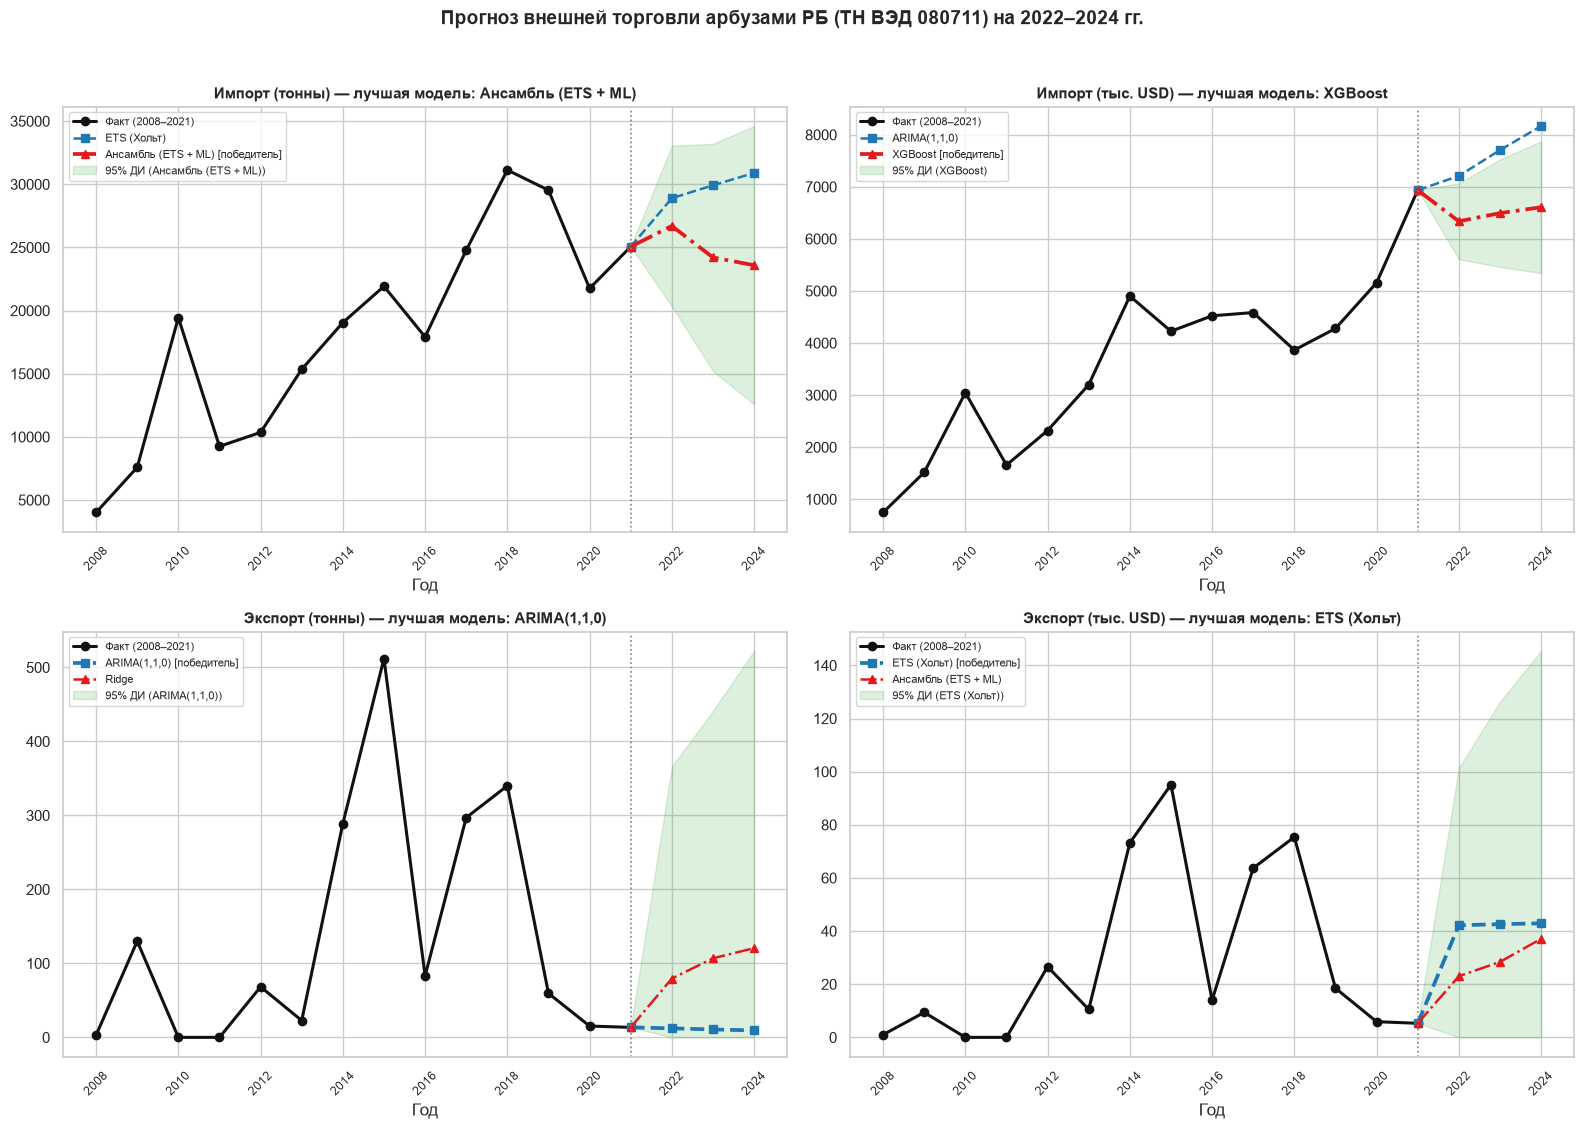

График сохранен: D:\Влад\Учеба\data-analyst-test\task_2\figures\04_forecast_2022_2024.png

=== Итоговый прогноз на 2022–2024 гг. (по лучшим моделям) ===


,Показатель,Модель,Год,Прогноз,95% ДИ (низ),95% ДИ (верх)
0,Импорт (тонны),Ансамбль (ETS + ML),2022,26696.3,20332.7,33060.0
1,Импорт (тонны),Ансамбль (ETS + ML),2023,24205.9,15206.3,33205.4
2,Импорт (тонны),Ансамбль (ETS + ML),2024,23591.3,12569.1,34613.4
3,Импорт (тыс. USD),XGBoost,2022,6337.8,5607.5,7068.1
4,Импорт (тыс. USD),XGBoost,2023,6494.7,5461.9,7527.5
5,Импорт (тыс. USD),XGBoost,2024,6607.8,5342.9,7872.7
6,Экспорт (тонны),"ARIMA(1,1,0)",2022,12.2,0.0,366.0
7,Экспорт (тонны),"ARIMA(1,1,0)",2023,10.7,0.0,441.4
8,Экспорт (тонны),"ARIMA(1,1,0)",2024,9.3,0.0,522.3
9,Экспорт (тыс. USD),ETS (Хольт),2022,42.2,0.0,101.4


In [10]:
fx_2008_2024 = df_exog_all["byn_usd_mean"].values
hist_years = df["year"].values
fut_years = np.array([2022, 2023, 2024])
plot_years = np.concatenate([[hist_years[-1]], fut_years])

forecast_rows = []
fig, axes = plt.subplots(2, 2, figsize=(16, 11.5))
axes = axes.flatten()

for idx, (col, label) in enumerate(target_specs):
    y_full = df[col].values
    winner_name = best_models_by_col[col]

    # Обучаем все 7 моделей на 2008-2021 гг.
    full_res = run_all_models(y_full, df_exog_all, steps=3)

    for m_name, (preds, lo, hi) in full_res.items():
        for yr, p_val, l_val, h_val in zip(fut_years, preds, lo, hi):
            forecast_rows.append({
                "Показатель": label,
                "Модель": m_name,
                "Победитель": "Да" if m_name == winner_name else "",
                "Год": int(yr),
                "Прогноз": round(float(p_val), 1),
                "95% ДИ (низ)": round(float(l_val), 1),
                "95% ДИ (верх)": round(float(h_val), 1),
            })

    # Выбираем ориентиры для графика: лучший стат., лучший ML и победителя
    sub_val = df_val[df_val["code"] == col].set_index("Модель")["RMSE"]
    best_stat = "ETS (Хольт)" if sub_val["ETS (Хольт)"] <= sub_val["ARIMA(1,1,0)"] else "ARIMA(1,1,0)"
    ml_candidates = ["Ridge", "Ridge + курс и погода", "XGBoost", "XGBoost + курс и погода", "Ансамбль (ETS + ML)"]
    best_ml = sub_val.loc[ml_candidates].idxmin()

    candidates_to_show = []
    for name, style in [
        (best_stat, ("#1f78b4", "--", "s")),
        (best_ml, ("#e31a1c", "-.", "^")),
        (winner_name, ("#2ca02c", "-", "o")),
    ]:
        if name not in [x[0] for x in candidates_to_show]:
            candidates_to_show.append((name, style))

    ax = axes[idx]
    ax.plot(hist_years, y_full, marker="o", color="#111111", linewidth=2.2, label="Факт (2008–2021)")

    for m_name, (color, ls, marker) in candidates_to_show:
        preds, _, _ = full_res[m_name]
        line_vals = np.concatenate([[y_full[-1]], preds])
        is_win = (m_name == winner_name)
        lw = 2.7 if is_win else 1.8
        tag = " [победитель]" if is_win else ""
        ax.plot(plot_years, line_vals, marker=marker, linestyle=ls, color=color, linewidth=lw, label=f"{m_name}{tag}")

    # 95% доверительный интервал для лучшей модели
    w_preds, w_lo, w_hi = full_res[winner_name]
    ci_lo_line = np.concatenate([[y_full[-1]], w_lo])
    ci_hi_line = np.concatenate([[y_full[-1]], w_hi])
    ax.fill_between(plot_years, ci_lo_line, ci_hi_line, color="#2ca02c", alpha=0.16, label=f"95% ДИ ({winner_name})")

    ax.axvline(2021, color="gray", linestyle=":", linewidth=1.2)
    ax.set_title(f"{label} — лучшая модель: {winner_name}", fontweight="bold", fontsize=11)
    ax.set_xlabel("Год")
    ax.set_xticks(np.arange(2008, 2025, 2))
    ax.tick_params(axis="x", rotation=45, labelsize=8.5)
    ax.legend(loc="upper left", fontsize=8.2)

plt.suptitle("Прогноз внешней торговли арбузами РБ (ТН ВЭД 080711) на 2022–2024 гг.", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
fc_fig_path = FIGURES_DIR / "04_forecast_2022_2024.png"
plt.savefig(fc_fig_path, dpi=200)
plt.show()

df_forecasts = pd.DataFrame(forecast_rows)
df_forecasts.to_csv(PROCESSED_DIR / "forecasts_2022_2024.csv", index=False)
print(f"График сохранен: {fc_fig_path}\n")

print("=== Итоговый прогноз на 2022–2024 гг. (по лучшим моделям) ===")
df_best_fc = df_forecasts[df_forecasts["Победитель"] == "Да"].drop(columns=["Победитель"])
display(df_best_fc.reset_index(drop=True))

### Выводы по прогнозу на 2022-2024 гг.

1. **Импорт (физический объём, тонны) - модель `Ансамбль (ETS + ML)`:** прогнозируется плавная стабилизация ввоза на уровне **26 696,3 т в 2022 г.**, **24 205,9 т в 2023 г.** и **23 591,3 т в 2024 г.** (95% ДИ к 2024 г.: `12 569,1 - 34 613,4 т`). Жаркие летние сезоны 2022-2024 гг. (`36-40` дней от 25°C) поддерживают высокий потребительский спрос, однако рост курса доллара до `3,25 BYN` сдерживает дальнейшее расширение физических закупок.
2. **Импорт (стоимость, тыс. USD) - модель `XGBoost`:** валютные затраты на импорт оцениваются в **6 337,8 тыс. USD в 2022 г.**, **6 494,7 тыс. USD в 2023 г.** и **6 607,8 тыс. USD в 2024 г.** (95% ДИ к 2024 г.: `5 342,9 - 7 872,7 тыс. USD`). После ценового скачка 2021 года (`6 936,0 тыс. USD`) модель закладывает небольшую коррекцию с последующим умеренным ростом из-за сохранения высоких контрактных цен и стоимости логистики.
3. **Экспорт (количество и стоимость) - `ARIMA(1,1,0)` и `ETS (Хольт)`:** базовый прогноз указывает на сохранение минимальных поставок - **12,2 / 10,7 / 9,3 т** по физическому объёму и **42,2 / 42,6 / 42,9 тыс. USD** по выручке. Широкий верхний предел 95% доверительного интервала (до `366-522 т` и `101-145 тыс. USD`) отражает высокую волатильность прошлых лет и вероятность разовых реэкспортных сделок.

---

## 5. Ключевые результаты и общие выводы исследования

### Сводная таблица результатов по показателям

| Показатель | Среднее за 2008-2021 | Факт 2021 | Лучшая модель (Walk-Forward, min RMSE) | Прогноз 2022 | Прогноз 2023 | Прогноз 2024 |
| :--- | :---: | :---: | :--- | :---: | :---: | :---: |
| **Импорт, тонн** | 18 368,0 | 25 061,0 | Ансамбль (ETS + ML с курсом и погодой) | 26 696,3 | 24 205,9 | 23 591,3 |
| **Импорт, тыс. USD** | 3 639,6 | 6 936,0 | XGBoost (базовый на приростах) | 6 337,8 | 6 494,7 | 6 607,8 |
| **Экспорт, тонн** | 131,0 | 13,5 | ARIMA(1,1,0) | 12,2 | 10,7 | 9,3 |
| **Экспорт, тыс. USD** | 28,5 | 5,3 | ETS (Хольт с затухающим трендом) | 42,2 | 42,6 | 42,9 |

### Главные выводы по блокам задачи

1. **Структура рынка и декомпозиция (2008-2021 гг.):**
   - Беларусь выступает чистым импортёром свежих арбузов (средний импорт превышает экспорт более чем в 130 раз). Разложение рядов фильтром Ходрика-Прескотта (`lambda = 6.25`) выявило устойчивый восходящий тренд импорта вплоть до фазы насыщения рынка в 2018-2021 гг. (`22-31 тыс. т` в год), тогда как внутригодовая сезонность в годовых агрегатах равна нулю.
   - В стоимостном импорте ключевую роль в последние годы сыграл ценовой фактор: при снижении тоннажа с `31,1 тыс. т` (2018 г.) до `25,1 тыс. т` (2021 г.) сумма закупок выросла с `3,87` до рекордных `6,94 млн USD` из-за двукратного удорожания средней цены тонны (`124,2 -> 276,8 $/т`).
   - Экспорт не имеет устойчивого тренда и представляет собой эпизодический реэкспорт с пиками в 2014-2018 гг. и затуханием к 2020-2021 гг.

2. **Влияние обменного курса BYN/USD и погоды:**
   - Сравнение годовых уровней даёт высокую положительную корреляцию курса с импортом (`Спирмен = +0,868` по стоимости и `+0,820` по тоннажу, `p < 0,001`), которая объясняется общим ростом обоих рядов во времени, а не стимулирующим эффектом слабой валюты.
   - Переход к годовым приростам вскрывает реальную реакцию спроса: резкие скачки курса `BYN/USD` статистически значимо сокращают физический ввоз арбузов (`Спирмен = -0,665`, `p = 0,013` - провалы 2011, 2016 и 2020 гг.). Для стоимости импорта в USD связь в приростах слабая и незначимая (`-0,264`, `p = 0,384`), так как сокращение тоннажа перекрывалось колебаниями долларовых контрактных цен.
   - Летняя жара выступает вторым значимым драйвером потребления: число дней с температурой `>= 25°C` положительно коррелирует с объёмом ввоза (`Спирмен = +0,633`, `p = 0,015`), объясняя в том числе рекордный всплеск импорта в аномально жарком 2010 году. Экспорт ни от курса рубля, ни от погоды в Беларуси не зависит.

3. **Выбор моделей и методологический итог:**
   - Проверка 7 моделей на скользящем окне (`Walk-Forward`, 2016-2021 гг.) показала, что добавление экзогенных факторов (курса `BYN/USD` и летней погоды) существенно повышает точность ML-моделей именно там, где работает экономика внутреннего спроса - на физическом импорте в тоннах (ошибка `RMSE` у `XGBoost` снизилась с `7 404,7` до `5 335,1`, а победителем стал `Ансамбль ETS + ML` с `RMSE = 4 897,1` и `MAPE = 17,8%`).
   - Для стоимостного импорта лучшим оказался базовый `XGBoost` на приростах (`MAPE = 13,3%`), а на нестабильных рядах экспорта с близкой к нулю базой последних лет классические статистические модели (`ARIMA` и `ETS`) превзошли машинное обучение по устойчивости.

4. **Ограничения исследования:**
   - Малая длина годового ряда (`N = 14`) ограничивает сложность обучаемых моделей и расширяет доверительные интервалы на трёхлетнем горизонте; переход к помесячным таможенным данным позволил бы явно моделировать летнюю сезонность (июнь-сентябрь).
   - Прогнозы на 2022-2024 гг. опираются на исторические закономерности 2008-2021 гг. и фактические метео- и валютные данные, но не могут напрямую учитывать нерыночные сдвиги в международной логистике и географии поставок после 2021 года.